In [51]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import tensorflow as tf
import pickle
import os
import sys
sys.path.append("..")
from src.model import SentimentANN

In [52]:
if not os.path.exists('../models'):
    os.makedirs('../models')

In [53]:
data = pd.read_csv("../all_data/clean_data/temiz_genel_veri.csv")
data.head()

,label,description
0,0,ordered dark cherries received gooseberries so...
1,0,beğenmedim ürünün kalıbı berbat aldığım ayakka...
2,0,bought sandal wanted more stylish but casual s...
3,0,bir yıldız kötü
4,1,kedim bayıldı öncelikle ürün gayet kaliteli ke...


In [54]:
VOCAB_SIZE = 30000
MAX_LEN = 130
EMBED_DIM = 128
HIDDEN_DIM = 64
BATCH_SIZE = 256
EPOCHS = 5
LEARNING_RATE = 0.001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan Cihaz: {device}")

Kullanılan Cihaz: cuda


In [55]:
tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words = VOCAB_SIZE,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(data["description"])

with open('../models/tokenizer.pickle',"wb") as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [56]:
sequences = tokenizer.texts_to_sequences(data["description"])

X = tf.keras.preprocessing.sequence.pad_sequences(
    sequences, 
    maxlen=MAX_LEN, 
    padding='post', 
    truncating='post'
)
y = data['label'].values

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2,random_state=42)
print(f"Sözlük boyutu: {VOCAB_SIZE}")

Sözlük boyutu: 30000


In [57]:
class SentimentDataset(Dataset):
    def __init__(self,X,y):
        self.X = torch.tensor(X, dtype=torch.long).to(device)
        self.y = torch.tensor(y, dtype=torch.long).to(device)

    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx] 
    
train_loader = DataLoader(SentimentDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(SentimentDataset(X_test, y_test), batch_size=BATCH_SIZE)

In [58]:
model = SentimentANN(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

loss_fn = nn.BCELoss()
optimizer = optim.Adam(params=model.parameters(), lr=LEARNING_RATE)

print(model)

SentimentANN(
  (embedding): Embedding(30000, 128)
  (layers): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
    (6): Sigmoid()
  )
)


In [59]:
train_losses=[]
test_losses=[]
test_accuracy = []
train_accuracy = []

print(f"Eğitim {device} üzerinde başlıyor..")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device).view(-1,1).float()

        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predicted = (outputs > 0.5).float()
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct_train / total_train

    train_losses.append(epoch_train_loss)
    train_accuracy.append(epoch_train_acc)


    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad(): 
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device).view(-1, 1).float()
            
            outputs = model(inputs)
            loss_test = loss_fn(outputs, labels)
            
            running_test_loss += loss_test.item()
            predicted = (outputs > 0.5).float()
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            
    
    epoch_test_loss = running_test_loss / len(test_loader)
    epoch_test_acc = 100 * correct_test / total_test
    
    test_losses.append(epoch_test_loss)
    test_accuracy.append(epoch_test_acc)
    
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] -> "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: %{epoch_train_acc:.2f} | "
          f"Test Loss: {epoch_test_loss:.4f}, Test Acc: %{epoch_test_acc:.2f}")

print("\nEğitim Tamamlandı! Modeli kaydedebilirsin.")

Eğitim cuda üzerinde başlıyor..
Epoch [1/5] -> Train Loss: 0.5622, Train Acc: %66.77 | Test Loss: 0.3114, Test Acc: %87.17
Epoch [2/5] -> Train Loss: 0.2931, Train Acc: %88.33 | Test Loss: 0.2583, Test Acc: %89.50
Epoch [3/5] -> Train Loss: 0.2499, Train Acc: %90.27 | Test Loss: 0.2484, Test Acc: %89.91
Epoch [4/5] -> Train Loss: 0.2277, Train Acc: %91.33 | Test Loss: 0.2402, Test Acc: %90.21
Epoch [5/5] -> Train Loss: 0.2130, Train Acc: %91.94 | Test Loss: 0.2380, Test Acc: %90.42

Eğitim Tamamlandı! Modeli kaydedebilirsin.


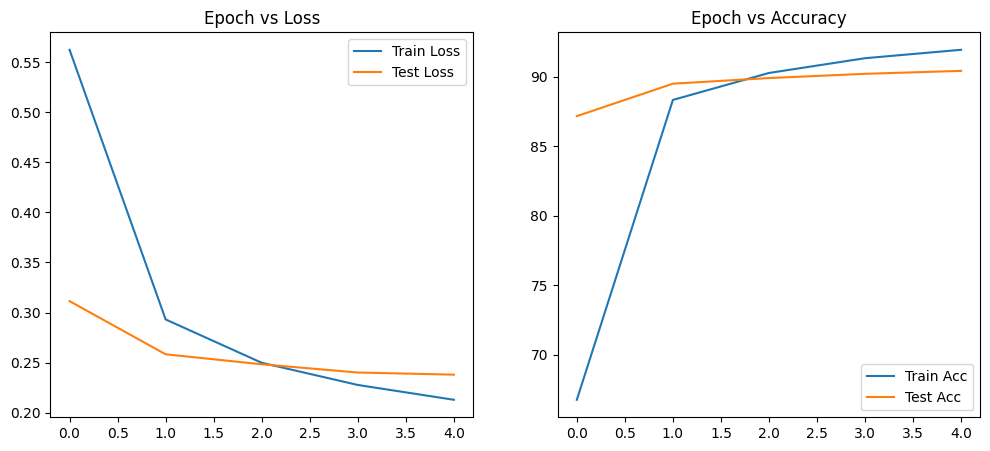

In [60]:
import matplotlib.pyplot as plt

# Kayıp (Loss) Grafiği
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title('Epoch vs Loss')
plt.legend()

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 2)
plt.plot(train_accuracy, label='Train Acc')
plt.plot(test_accuracy, label='Test Acc')
plt.title('Epoch vs Accuracy')
plt.legend()

plt.show()

In [61]:
torch.save(model.state_dict(), '../models/sentiment_model.pth')
with open('../models/tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

print("Model ve ağırlıklar kaydedildi")

Model ve ağırlıklar kaydedildi
